Cell 1:Install

In [47]:
# Install libraries and download the hand-detector model file
!pip -q install mediapipe kagglehub
!wget -q -O /content/hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task
!ls -la /content/hand_landmarker.task
# NOW: Runtime -> Restart session

-rw-r--r-- 1 root root 7819105 Apr 26  2023 /content/hand_landmarker.task


Cell 2: Imports and detectors

In [48]:
import os, glob, re, string, zipfile
import numpy as np, cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
import matplotlib.pyplot as plt

BASE = '/content/HandTalkAI'
for sub in ['landmarks/kaggle', 'models', 'people']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)

# Detector 1: normal settings
detector = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path='/content/hand_landmarker.task'),
    running_mode=vision.RunningMode.IMAGE, num_hands=1,
    min_hand_detection_confidence=0.5))

# Detector 2: lenient settings, used as a retry for hard photos
detector_low = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path='/content/hand_landmarker.task'),
    running_mode=vision.RunningMode.IMAGE, num_hands=1,
    min_hand_detection_confidence=0.2, min_hand_presence_confidence=0.2))

LETTERS = list(string.ascii_uppercase)   # A..Z
print("Setup OK, MediaPipe", mp.__version__)

Setup OK, MediaPipe 1.2.0


Cell 3:My Own Data

In [49]:
from google.colab import files
up = files.upload()                                   # choose your zip file
for z in up:
    zipfile.ZipFile(z).extractall(f'{BASE}/people')   # unpack into the people folder

n = len([f for f in glob.glob(f'{BASE}/people/**/*.*', recursive=True)
         if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))])
print("Photos found:", n)                             # expect 242

Saving People.zip to People (1).zip
Photos found: 242


Cell 4: Photo → 21 points → 63 normalized numbers

In [50]:
def _try(det, img_bgr):
    """Run one detector on one image. Returns the 21 points or None."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
    res = det.detect(mp_img)
    return res.hand_landmarks[0] if res.hand_landmarks else None

def extract_landmarks(img_bgr):
    """Returns 63 numbers describing hand SHAPE only, or None if no hand found."""
    h, w = img_bgr.shape[:2]
    pad = int(0.35 * max(h, w))                       # border helps on tight crops
    fill = tuple(int(c) for c in np.median(img_bgr.reshape(-1, 3), axis=0))
    padded = cv2.copyMakeBorder(img_bgr, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=fill)

    lm = None
    for det in (detector, detector_low):              # normal first, then lenient
        for im in (img_bgr, padded):                  # original first, then padded
            lm = _try(det, im)
            if lm is not None: break
        if lm is not None: break
    if lm is None:
        return None

    pts = np.array([[p.x, p.y, p.z] for p in lm], dtype=np.float32)   # (21, 3)
    pts -= pts[0]                                     # wrist = origin  -> position independent
    scale = np.linalg.norm(pts[:, :2], axis=1).max()
    if scale < 1e-6: return None
    pts /= scale                                      # divide by size  -> distance independent
    return pts.flatten()                              # 63 numbers

Cell 5: Kaggle landmarks

In [51]:
import kagglehub
path = kagglehub.dataset_download("grassknoted/asl-alphabet")
train_dir = glob.glob(f'{path}/**/asl_alphabet_train', recursive=True)[-1]

PER_CLASS = 1000                                      # images used per letter
out_dir = f'{BASE}/landmarks/kaggle'

for L in LETTERS:
    f = f'{out_dir}/{L}.npy'
    if os.path.exists(f): continue                    # already done, skip
    imgs = sorted(glob.glob(f'{train_dir}/{L}/*.jpg'))[:PER_CLASS]
    feats = []
    for p in imgs:
        v = extract_landmarks(cv2.imread(p))
        if v is not None: feats.append(v)
    np.save(f, np.array(feats))
    print(L, len(feats), "/", len(imgs))

# Load everything into memory
Xk, yk = [], []
for L in LETTERS:
    a = np.load(f'{out_dir}/{L}.npy'); Xk.append(a); yk += [L] * len(a)
Xk, yk = np.vstack(Xk), np.array(yk)
print("Kaggle samples:", Xk.shape)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Kaggle samples: (23737, 63)


In [52]:
!cd /content && zip -rq landmarks.zip HandTalkAI/landmarks
files.download('/content/landmarks.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Landmarks from your people’s photos (automatic labels)

In [53]:
root = f'{BASE}/people'

def label_from_path(p):
    """Letter from the folder name (A, A_) or, if missing, from the file name."""
    parts = os.path.relpath(p, root).split(os.sep)
    c = parts[-2].strip('_ ')
    if len(c) == 1 and c.isalpha(): return c.upper()
    m = re.search(r'(?<![A-Za-z])([A-Za-z])(?![A-Za-z])', os.path.splitext(parts[-1])[0])
    return m.group(1).upper() if m else None

def person_from_path(p):
    """Person name = the path part that starts with 'person' (Person_1, Person_2...)."""
    for part in os.path.relpath(p, root).split(os.sep):
        if part.lower().startswith('person'): return part
    return 'unknown'

all_files = [f for f in glob.glob(f'{root}/**/*.*', recursive=True)
             if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]

X_p, y_p, g_p, skipped = [], [], [], 0
for p in all_files:
    lab = label_from_path(p)
    img = cv2.imread(p)
    v = None if (lab is None or img is None) else extract_landmarks(img)
    if v is None: skipped += 1; continue              # no hand found -> skip photo
    X_p.append(v); y_p.append(lab); g_p.append(person_from_path(p))

X_p, y_p, g_p = np.array(X_p), np.array(y_p), np.array(g_p)
print("Used:", len(X_p), "| skipped (no hand):", skipped, "| total:", len(all_files))
print("Per person:", {str(g): int((g_p == g).sum()) for g in sorted(set(g_p))})

Used: 242 | skipped (no hand): 0 | total: 242
Per person: {'Person_1': 78, 'Person_2': 82, 'Person_3': 82}


Cell 7: Model, augmentation, training function

In [54]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import shuffle

le = LabelEncoder().fit(LETTERS)                      # letters <-> numbers 0..25
yk_enc = le.transform(yk)

def augment(X, n_copies, seed=0):
    """Make slightly rotated, stretched and noisy copies of landmark sets."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_copies):
        P = X.reshape(-1, 21, 3).copy()
        ang = np.deg2rad(rng.uniform(-20, 20, (len(P), 1)))       # rotate +-20 degrees
        c, s = np.cos(ang), np.sin(ang)
        x, y = P[:, :, 0].copy(), P[:, :, 1].copy()
        P[:, :, 0] = c * x - s * y
        P[:, :, 1] = s * x + c * y
        P[:, :, :2] *= rng.uniform(0.9, 1.1, (len(P), 1, 2))      # stretch +-10%
        P += rng.normal(0, 0.02, P.shape)                          # small noise
        P -= P[:, 0:1, :]                                          # wrist back to origin
        out.append(P.reshape(-1, 63))
    return np.vstack(out)

def build():
    """The ANN: 63 numbers in, 26 letters out."""
    m = models.Sequential([
        layers.Input(shape=(63,)),
        layers.Dense(256, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(128, activation='relu'), layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(26, activation='softmax')])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def train(Xp_tr=None, yp_tr=None, epochs=25):
    """Train on Kaggle (+ optional people photos). No validation_split (it leaks)."""
    tf.keras.utils.set_random_seed(42)
    Xs = [Xk, augment(Xk, 1)];  ys = [yk_enc, yk_enc]
    if Xp_tr is not None and len(Xp_tr):
        Xs += [Xp_tr, augment(Xp_tr, 30)]             # people photos get 30 augmented copies
        ys += [yp_tr] * 31
    X, y = shuffle(np.vstack(Xs), np.concatenate(ys), random_state=42)
    m = build()
    m.fit(X, y, epochs=epochs, batch_size=64, verbose=0)
    return m

yp_enc = le.transform(y_p)
print("Ready")

Ready


Cell 8: Results table

In [56]:
persons = sorted(set(g_p))
rows, all_true, all_pred = [], [], []

# (a) Kaggle only: never saw any of your people
m0 = train()
kaggle_only = {p: m0.evaluate(X_p[g_p == p], yp_enc[g_p == p], verbose=0)[1] for p in persons}

# (b) Kaggle + the other 2 people, tested on the held-out person
for p in persons:
    tr = g_p != p
    m = train(X_p[tr], yp_enc[tr])
    Xt, yt = X_p[g_p == p], yp_enc[g_p == p]
    pred = m.predict(Xt, verbose=0).argmax(1)
    all_true += list(yt); all_pred += list(pred)
    rows.append((p, kaggle_only[p], float((pred == yt).mean())))

print(f"{'Held-out person':16s}{'Kaggle only':>14s}{'Kaggle + others':>18s}")
for p, a, b in rows: print(f"{p:16s}{a:14.1%}{b:18.1%}")
print(f"{'AVERAGE':16s}{np.mean([r[1] for r in rows]):14.1%}{np.mean([r[2] for r in rows]):18.1%}")

Held-out person    Kaggle only   Kaggle + others
Person_1                 61.5%             75.6%
Person_2                 37.8%             57.3%
Person_3                 34.1%             61.0%
AVERAGE                  44.5%             64.6%


Cell 9: Confusion matrix and per-letter report

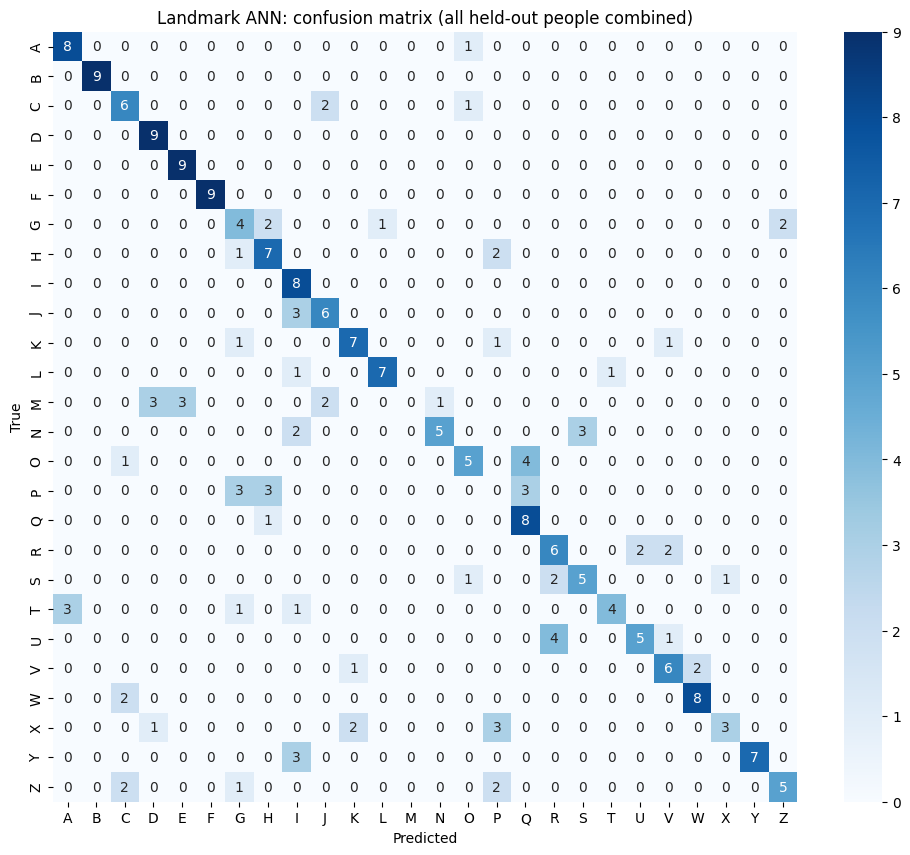

              precision    recall  f1-score   support

           A       0.73      0.89      0.80         9
           B       1.00      1.00      1.00         9
           C       0.55      0.67      0.60         9
           D       0.69      1.00      0.82         9
           E       0.75      1.00      0.86         9
           F       1.00      1.00      1.00         9
           G       0.36      0.44      0.40         9
           H       0.54      0.70      0.61        10
           I       0.44      1.00      0.62         8
           J       0.60      0.67      0.63         9
           K       0.70      0.70      0.70        10
           L       0.88      0.78      0.82         9
           M       0.00      0.00      0.00         9
           N       0.83      0.50      0.62        10
           O       0.62      0.50      0.56        10
           P       0.00      0.00      0.00         9
           Q       0.53      0.89      0.67         9
           R       0.50    

In [57]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

all_true, all_pred = np.array(all_true), np.array(all_pred)
present = sorted(set(all_true) | set(all_pred))
names = le.inverse_transform(present)

cm = confusion_matrix(all_true, all_pred, labels=present)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.title('Landmark ANN: confusion matrix (all held-out people combined)')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

print(classification_report(all_true, all_pred, labels=present,
                            target_names=names, zero_division=0))

Cell 10: Final model on everyone, saved

In [58]:
final = train(X_p, yp_enc)                            # Kaggle + all 3 people
final.save(f'{BASE}/models/handtalk_landmark_ann.keras')
np.save(f'{BASE}/models/classes.npy', le.classes_)

!cd /content && zip -rq models.zip HandTalkAI/models
from google.colab import files
files.download('/content/models.zip')                 # keep this on your computer

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cell 11: Demo, upload any photo → predicted letter

Saving WhatsApp Image 2026-10-29 at 21.38.37.jpeg to WhatsApp Image 2026-10-29 at 21.38.37.jpeg


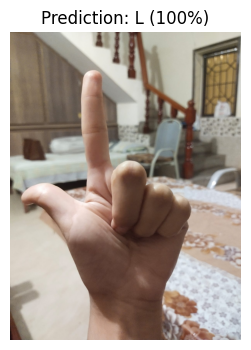

Top 3: [(np.str_('L'), '100%'), (np.str_('G'), '0%'), (np.str_('I'), '0%')]


In [60]:
from google.colab import files
up = files.upload()
for name in up:
    img = cv2.imread(name)
    v = extract_landmarks(img)
    plt.figure(figsize=(4, 4)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off')
    if v is None:
        plt.title("No hand detected"); plt.show(); continue
    probs = final.predict(v[None, :], verbose=0)[0]
    top3 = probs.argsort()[::-1][:3]
    plt.title(f"Prediction: {le.classes_[top3[0]]} ({probs[top3[0]]:.0%})"); plt.show()
    print("Top 3:", [(le.classes_[i], f"{probs[i]:.0%}") for i in top3])